<a href="https://colab.research.google.com/github/Nthabiseng3310/Machine-Learning-Research-Assignment/blob/main/Research_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Titanic dataset

#Step 1: Import the libraries
We import pandas to work with the data. We also import Seaborn to load the Titanic dataset, and scikit-learn tools for splitting and preparing the data.

In [2]:
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import numpy as np

#Step 2: Load the dataset
We load the Titanic dataset into a pandas DataFrame.

In [3]:
df = sns.load_dataset("titanic")

# Show the first five rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


#Step 3: Inspect the data
Before cleaning, we check:
1. Shape: the number of rows and columns.
2. Data types: whether each column contains numbers, text, or another type.
3. Missing values: how many empty values each column has.

In [4]:
#Checking for Number of rows and columns,891 rows and 15 Columns
print(df.shape)



(891, 15)


In [5]:
#Checking for Data types
print(df.dtypes)


survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object


In [6]:
#Checking for Missing values in each column
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [19]:
# Calculate the median of the 'age' column
median_age = df['age'].median()

# Fill missing values in 'age' with the median
df['age'] = df['age'].fillna(median_age)

In [20]:
# Calculate the median age using ONLY the training features to prevent data leakage
train_median_age = X_train_encoded['age'].median()

# Fill the missing ages in both encoded train and test datasets
X_train_encoded['age'] = X_train_encoded['age'].fillna(train_median_age)
X_test_encoded['age'] = X_test_encoded['age'].fillna(train_median_age)

# Confirm that no null values remain in the age column
print("Missing values in training age:", X_train_encoded['age'].isnull().sum())
print("Missing values in testing age:", X_test_encoded['age'].isnull().sum())

Missing values in training age: 0
Missing values in testing age: 0


In [7]:
#Step 4: Selecting the columns to use as features and target
columns = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]



In [8]:
#Step 5: we are Removing rows where the target is missing, because we cannot train
#a model when the correct answer (target) is unknown.
data = df[columns].dropna(subset=["survived"])

In [9]:
#Creating the features and target variables
X = data.drop("survived", axis=1)  # Features:X holds all the independent variables (passenger class, sex, age, etc.) that the model will use to make predictions.
y = data["survived"]               # Target:Isolates the survived column into our target vector (y).

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 7)
Target shape: (891,)


In [10]:
#Step 6: Split the data into training and test sets (80/20)- 80% is used to train the model.
#20% is kept for testing.
#We split the data before fitting imputers, encoders, or scalers.
#This order helps prevent data leakage. The test data must not influence the values learned during preprocessing.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42, #makes the split repeatable.
    stratify=y #keeps a similar proportion of survivors and non-survivors in both sets.
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (712, 7)
Testing features: (179, 7)
Training target: (712,)
Testing target: (179,)


In [14]:
#Step 7:Categorical Encoding

# One-hot encode categorical columns
X_train_encoded = pd.get_dummies(X_train, columns=['sex', 'embarked'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['sex', 'embarked'], drop_first=True)

# Align columns to ensure test set doesn't have missing or extra categories
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

#Preview features including encoded column (sex_male) from the encoded training set
print(X_train_encoded[['age', 'fare', 'sex_male']].head())

      age      fare  sex_male
692   NaN   56.4958      True
481   NaN    0.0000      True
527   NaN  221.7792      True
855  18.0    9.3500     False
801  31.0   26.2500     False


In [15]:
# Step 8: Round the 'fare' column to 2 decimal places
X_train_encoded['fare'] = X_train_encoded['fare'].round(2)
X_test_encoded['fare'] = X_test_encoded['fare'].round(2)

# Preview the updated columns
print(X_train_encoded[['age', 'fare', 'sex_male']].head())

      age    fare  sex_male
692   NaN   56.50      True
481   NaN    0.00      True
527   NaN  221.78      True
855  18.0    9.35     False
801  31.0   26.25     False


In [21]:
#Step 9: Feature Scaling

from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Define numerical columns to scale
num_cols = ['age', 'fare']

# Fit the scaler on the training set and transform both training and test sets
X_train_encoded[num_cols] = scaler.fit_transform(X_train_encoded[num_cols])
X_test_encoded[num_cols] = scaler.transform(X_test_encoded[num_cols])

# Preview the scaled features
print("Scaled Training Data (first 5 rows):")
display(X_train_encoded[num_cols].head())

Scaled Training Data (first 5 rows):


,age,fare
692,-0.081135,0.513897
481,-0.081135,-0.662566
527,-0.081135,3.955416
855,-0.887827,-0.467877
801,0.110934,-0.115979


In [22]:
# Step 10: Train a Classification Model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize the model
model = LogisticRegression()

# 2. Train (fit) the model using the preprocessed training data
model.fit(X_train_encoded, y_train)

# 3. Make predictions on the test set
y_pred = model.predict(X_test_encoded)

# 4. Evaluate the model performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8044692737430168

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



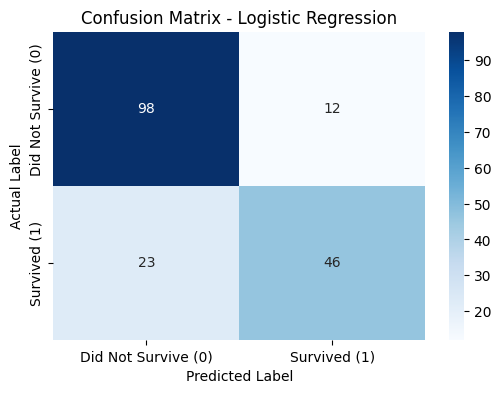

In [23]:
# Step 11: Plot Confusion Matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Display the confusion matrix using a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Did Not Survive (0)', 'Survived (1)'],
            yticklabels=['Did Not Survive (0)', 'Survived (1)'])

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

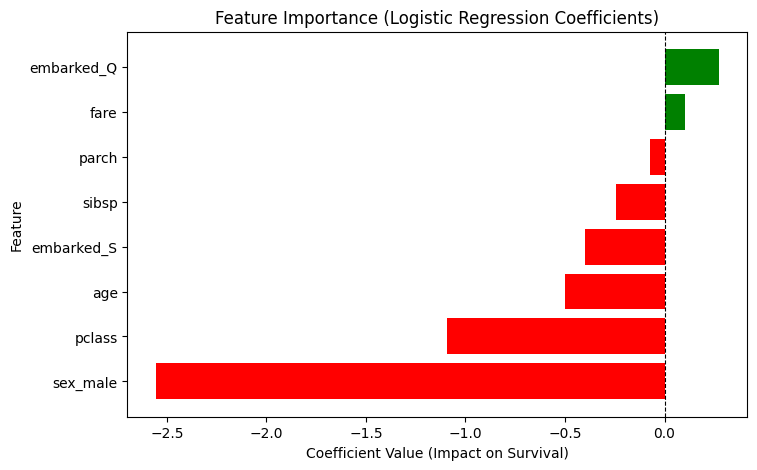

In [24]:
# Step 12: Feature Importance / Coefficient Analysis
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract feature names and their corresponding logistic regression coefficients
feature_names = X_train_encoded.columns
coefficients = model.coef_[0]

# 2. Create a DataFrame to sort and visualize feature impact
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=True)

# 3. Plot horizontal bar chart
plt.figure(figsize=(8, 5))
plt.barh(importance_df['Feature'], importance_df['Coefficient'], color=['red' if x < 0 else 'green' for x in importance_df['Coefficient']])
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel('Coefficient Value (Impact on Survival)')
plt.ylabel('Feature')
plt.title('Feature Importance (Logistic Regression Coefficients)')
plt.show()